# Social Media Engagement Analytics Using Python

A Python analysis of social media engagement data: cleaning, exploration, statistics, visualization and insights.

Prepared by: **Ansania Salam**

## ⚙️ Setup

Import the libraries used in this project.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print("Libraries imported")

Libraries imported


NumPy and Pandas handle the data, Matplotlib, Seaborn and Plotly draw the charts, and SciPy is used once at the end to check whether differences between groups are real. The display options make sure wide tables show every column.

---
## 📥  Data Import & Setup

- Import the CSV using Pandas.

In [5]:
import pandas as pd
df = pd.read_csv(r"C:\Users\ansan\Downloads\social_media_engagement_5000.csv")


print("Shape:", df.shape)
print()
print(df.head())

Shape: (5000, 19)

   user_id   age  gender country  post_id post_type post_category    likes  comments  shares  watch_time_sec  impression_count   posted_at  follower_count  is_verified device_type sentiment  \
0    25795  43.0  Female  Brazil   496713     image       fitness   7011.0     354.0  1157.0            5726             44650  17-12-2022           81734        False      mobile  negative   
1    10860  33.0    Male  Brazil   157326      reel          food  11750.0    2606.0  1807.0            5947             80216  02-06-2023            5963        False      mobile  negative   
2    86820  32.0  Female      UK   109864      text          food   4862.0     344.0   955.0            6946             44858  07-05-2023          501783        False      tablet  positive   
3    64886  51.0   Other  France   848877      text       fitness   5350.0    1083.0  1049.0             229             70455  12-02-2023          480212        False      mobile  negative   
4    16265  34.0

`pd.read_csv()` loads the file into a DataFrame. There are 5,000 posts and 19 columns, covering the user (age, gender, country, followers, verified status), the post (type, category, hashtags, date, device, sentiment) and its results (likes, comments, shares, watch time, impressions, engagement rate).

- Check the data types.

In [6]:
print(df.dtypes)

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object


Two things need attention. `posted_at` is stored as text (`str`) even though it is a date. And `age`, `likes`, `comments` and `shares` are `float64` even though they are whole numbers, because missing values force a column to hold decimals. Both are fixed later.

- Convert the date column to datetime.

In [7]:
# the dates are written day-month-year, e.g. 17-12-2022, so the format is given explicitly
df['posted_at'] = pd.to_datetime(df['posted_at'], format='%d-%m-%Y')

print("Data type:", df['posted_at'].dtype)
print("Earliest post:", df['posted_at'].min().date())
print("Latest post  :", df['posted_at'].max().date())

Data type: datetime64[us]
Earliest post: 2022-01-01
Latest post  : 2023-12-31


The dates are written day first, so the format `%d-%m-%Y` is given. Without it, Pandas could read a date like 02-06-2023 as 6 February instead of 2 June. The posts run from 1 January 2022 to 31 December 2023. The column holds only the date, with no time of day, which matters for one of the questions at the end.

- Use NumPy arrays for basic array operations.

In [8]:
likes = df['likes'].to_numpy()
comments = df['comments'].to_numpy()
shares = df['shares'].to_numpy()
impressions = df['impression_count'].to_numpy()

total_engagement = likes + comments + shares            # element-wise addition
engagement_per_1k = total_engagement / impressions * 1000

print("Missing likes            :", np.isnan(likes).sum())
print("Average total engagement :", round(np.nanmean(total_engagement), 1))
print("Highest total engagement :", np.nanmax(total_engagement))
print("Median impressions       :", np.median(impressions))
print("Impressions (25th, 50th, 75th percentile):", np.percentile(impressions, [25, 50, 75]))
print("Median engagements per 1,000 impressions :", round(np.nanmedian(engagement_per_1k), 1))

Missing likes            : 150
Average total engagement : 12593.9
Highest total engagement : 24680.0
Median impressions       : 49934.5
Impressions (25th, 50th, 75th percentile): [24988.25 49934.5  74662.25]
Median engagements per 1,000 impressions : 253.0


`to_numpy()` turns a column into a NumPy array, and arithmetic on arrays works on every element at once, so no loop is needed. Missing values appear as `NaN`, which would spoil a normal `mean()`, so the `nan` versions (`nanmean`, `nanmax`, `nanmedian`) are used. They skip the 150 missing likes.

---
## 🧹 Data Cleaning

###  Cleaning Missing Data

- Detect missing values using `isnull()` and `isna()`.

In [9]:
missing = df.isnull().sum()

print("Missing values per column (isnull):")
print(missing[missing > 0])
print()
print("isna() gives the same answer:", df.isna().sum().equals(df.isnull().sum()))
print("Rows with at least one missing value:", df.isnull().any(axis=1).sum(), "out of", len(df))

Missing values per column (isnull):
age          150
gender       150
likes        150
comments     150
shares       150
sentiment    150
dtype: int64

isna() gives the same answer: True
Rows with at least one missing value: 838 out of 5000


`isnull()` and `isna()` do the same thing. Six columns have 150 missing values each: `age`, `gender`, `likes`, `comments`, `shares` and `sentiment`. The gaps fall on different rows, so 838 rows (about 17%) have at least one gap. Dropping all of them would throw away a sixth of the data, so most columns are filled instead.

- Handle the missing values using `dropna()`, `fillna()` and the median or mode.

**Numeric columns:** fill with the median.

In [10]:
for col in ['age', 'likes', 'comments', 'shares']:
    df[col] = df[col].fillna(df[col].median())

print(df[['age', 'likes', 'comments', 'shares']].isnull().sum())

age         0
likes       0
comments    0
shares      0
dtype: int64


The median is used for the numeric columns because it is not pulled by extreme values.

**Gender:** fill with a separate `Unknown` label.

In [11]:
df['gender'] = df['gender'].fillna('Unknown')

print(df['gender'].value_counts())

gender
Male       1699
Other      1581
Female     1570
Unknown     150
Name: count, dtype: int64


The usual choice for a text column is the mode (most frequent value), which here would label all 150 missing people as `Male`. That would invent 150 genders. A separate `Unknown` label is more honest, and it keeps the rows.

**Sentiment:** drop the rows with a missing value.

In [12]:
print("Rows before:", len(df))

df = df.dropna(subset=['sentiment'])

print("Rows after :", len(df))
print("Total missing values left:", df.isnull().sum().sum())

Rows before: 5000
Rows after : 4850
Total missing values left: 0


Sentiment is the basis of the sentiment analysis at the end, and it cannot be guessed. Filling it with the mode would add 150 made-up positive posts, so `dropna()` is used and those 150 rows (3%) are removed. Forward-fill and backward-fill were not used, because the rows are not in date order, so they would copy the value from an unrelated post.

###  Duplicate Handling

- Identify and remove duplicates.

In [13]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Repeated post_id values:", df['post_id'].duplicated().sum())
print()
print(df[df['post_id'].duplicated(keep=False)].sort_values('post_id')[['post_id', 'user_id', 'country', 'post_type', 'post_category', 'posted_at']].head(6))

df = df.drop_duplicates()
print()
print("Rows after drop_duplicates():", len(df))

Fully duplicated rows: 0
Repeated post_id values: 8

      post_id  user_id country post_type post_category  posted_at
3941   301157    73811  Canada     video       fashion 2023-10-03
3336   301157    82127   India     video       fashion 2022-09-09
4993   444417    82779      UK      text          food 2023-08-10
2153   444417    59104  Canada     image       fashion 2023-03-02
693    448492    15713     USA     image       fitness 2023-10-21
2117   448492    69189   India      text         music 2022-10-12

Rows after drop_duplicates(): 4850


There are no fully duplicated rows, so `drop_duplicates()` removes nothing. A few `post_id` values do repeat, but each pair is two different posts, with different users, countries, categories and dates, so they look like ID clashes and not copies. They are kept.

###  Data Formatting

- Fix incorrect data types.

In [14]:
for col in ['age', 'likes', 'comments', 'shares']:
    df[col] = df[col].astype(int)

print(df[['age', 'likes', 'comments', 'shares', 'is_verified', 'posted_at']].dtypes)

age                     int64
likes                   int64
comments                int64
shares                  int64
is_verified              bool
posted_at      datetime64[us]
dtype: object


With the gaps filled, these columns can be stored as whole numbers, which is what counts of likes and ages should be. `is_verified` is already a true/false column and `posted_at` was converted earlier.

- Standardize categories (for example the gender labels).

In [15]:
gender_map = {'male': 'Male', 'm': 'Male', 'female': 'Female', 'f': 'Female',
              'other': 'Other', 'unknown': 'Unknown'}
df['gender'] = df['gender'].str.strip().str.lower().map(gender_map)

for col in ['post_type', 'post_category', 'device_type']:
    df[col] = df[col].str.strip().str.lower()

df['country'] = df['country'].str.strip()

for col in ['gender', 'country', 'post_type', 'post_category', 'device_type']:
    print(col, "->", sorted(df[col].unique()))

print()
print("Gender labels not recognised:", df['gender'].isnull().sum())

gender -> ['Female', 'Male', 'Other', 'Unknown']
country -> ['Australia', 'Brazil', 'Canada', 'France', 'Germany', 'India', 'Japan', 'UAE', 'UK', 'USA']
post_type -> ['image', 'reel', 'text', 'video']
post_category -> ['education', 'fashion', 'fitness', 'food', 'lifestyle', 'music', 'tech', 'travel']
device_type -> ['desktop', 'mobile', 'tablet']

Gender labels not recognised: 0


The labels are trimmed and written in one consistent style, and the gender labels are mapped to `Male`, `Female`, `Other` and `Unknown`. In this dataset the labels were already consistent, so nothing changes, but the step guards against variants like `M`, `female ` or `MALE`. Country names are only trimmed, because `.title()` would turn `UK` into `Uk`.

- Correct unrealistic values in likes, comments and shares.

In [16]:
engagement = df['likes'] + df['comments'] + df['shares']
too_high = engagement > df['impression_count']

print("Posts where likes + comments + shares exceed the impressions:", too_high.sum(),
      f"({too_high.mean() * 100:.1f}%)")
print("Highest engagement_rate before the fix:", round(df['engagement_rate'].max(), 1))
print()
print(df.loc[too_high, ['likes', 'comments', 'shares', 'impression_count', 'engagement_rate']].nlargest(3, 'engagement_rate'))

# scale likes, comments and shares down together so that they add up to at most the impressions
scale = (df['impression_count'] / engagement).clip(upper=1)
for col in ['likes', 'comments', 'shares']:
    df[col] = np.floor(df[col] * scale).astype(int)

# recalculate the rate from the corrected numbers
df['engagement_rate'] = (df['likes'] + df['comments'] + df['shares']) / df['impression_count']

print()
print("Posts still above their impressions:", ((df['likes'] + df['comments'] + df['shares']) > df['impression_count']).sum())
print("Highest engagement_rate after the fix:", round(df['engagement_rate'].max(), 3))

Posts where likes + comments + shares exceed the impressions: 589 (12.1%)
Highest engagement_rate before the fix: 191.5

      likes  comments  shares  impression_count  engagement_rate
554   18513      2090    1420               115       191.504348
144   15055      1253    1616               147       121.931973
1947  10652       409     889               113       105.752212

Posts still above their impressions: 0
Highest engagement_rate after the fix: 1.0


`engagement_rate` is (likes + comments + shares) divided by impressions, and a post cannot get more reactions than the number of people who saw it. Yet a large number of posts do, for example 18,513 likes on a post with only 115 impressions, which gives an engagement rate of over 19,000%. There are no negative values to fix, so this is the unrealistic part of the data.

To correct it, likes, comments and shares are scaled down together for those posts so that they add up to at most the impressions. Their proportions stay the same, and `engagement_rate` is recalculated, so it now never goes above 1 (100%). Dropping those rows instead would remove about 12% of the data and mostly low-impression posts, which would distort the impressions analysis. Keep in mind that engagement figures for low-impression posts now come from this correction.

### Feature Cleaning

- Extract the hashtag count.

In [17]:
df['hashtag_count'] = df['hashtags'].str.split().str.len()

print(df[['hashtags', 'hashtag_count']].head())
print()
print(df['hashtag_count'].value_counts().sort_index())

                hashtags  hashtag_count
0  #foodie #travel #love              3
1               #fitness              1
2                #foodie              1
3    #music #foodie #fun              3
4                #travel              1

hashtag_count
1    1601
2    1654
3    1595
Name: count, dtype: int64


Hashtags are stored as one piece of text like `#foodie #travel #love`. Splitting it on spaces and counting the parts gives the number of hashtags. Every post has between 1 and 3.

- Clean the sentiment labels.

In [18]:
df['sentiment'] = df['sentiment'].str.strip().str.lower()

valid_sentiments = ['negative', 'neutral', 'positive']
print("All labels valid:", df['sentiment'].isin(valid_sentiments).all())
print()
print(df['sentiment'].value_counts())

All labels valid: True

sentiment
positive    2363
neutral     1527
negative     960
Name: count, dtype: int64


The labels are trimmed and lowercased, then checked against the three allowed values. All of them pass. Positive is the most common sentiment, followed by neutral and negative.

---
## 🔎 Data Exploration using Pandas

- View the dataset structure using `head()`, `tail()`, `shape` and `columns`.

In [19]:
print("First 5 rows:")
print(df.head())

print("\nLast 5 rows:")
print(df.tail())

print("\nShape:", df.shape)
print("\nColumns:", list(df.columns))

First 5 rows:
   user_id  age  gender country  post_id post_type post_category  likes  comments  shares  watch_time_sec  impression_count  posted_at  follower_count  is_verified device_type sentiment  \
0    25795   43  Female  Brazil   496713     image       fitness   7011       354    1157            5726             44650 2022-12-17           81734        False      mobile  negative   
1    10860   33    Male  Brazil   157326      reel          food  11750      2606    1807            5947             80216 2023-06-02            5963        False      mobile  negative   
2    86820   32  Female      UK   109864      text          food   4862       344     955            6946             44858 2023-05-07          501783        False      tablet  positive   
3    64886   51   Other  France   848877      text       fitness   5350      1083    1049             229             70455 2023-02-12          480212        False      mobile  negative   
4    16265   34   Other      UK   449706 

`head()` and `tail()` show the first and last rows, `shape` gives the number of rows and columns, and `columns` lists the column names. After cleaning there are 4,850 posts and 20 columns, one more than the original because of `hashtag_count`.

- Check the data types and info with `info()` and `dtypes`.

In [20]:
df.info()
print()
print(df.dtypes)

<class 'pandas.DataFrame'>
Index: 4850 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           4850 non-null   int64         
 1   age               4850 non-null   int64         
 2   gender            4850 non-null   str           
 3   country           4850 non-null   str           
 4   post_id           4850 non-null   int64         
 5   post_type         4850 non-null   str           
 6   post_category     4850 non-null   str           
 7   likes             4850 non-null   int64         
 8   comments          4850 non-null   int64         
 9   shares            4850 non-null   int64         
 10  watch_time_sec    4850 non-null   int64         
 11  impression_count  4850 non-null   int64         
 12  posted_at         4850 non-null   datetime64[us]
 13  follower_count    4850 non-null   int64         
 14  is_verified       4850 non-null   bool  

`info()` lists each column with its type and the number of non-empty values. Every column has all 4,850 values, which confirms the cleaning worked, and the types are now correct: whole numbers for counts, a datetime for `posted_at` and a true/false column for `is_verified`.

- Generate summary statistics using `describe()`.

In [21]:
print(df.describe().T.round(2))

                   count                        mean                  min                  25%                  50%                  75%                  max            std
user_id           4850.0                54497.526804              10055.0             32402.25              54189.0              77195.5              99963.0   26054.818524
age               4850.0                   38.439381                 13.0                 26.0                 38.0                 51.0                 64.0       14.69161
post_id           4850.0                548946.37134             100068.0            322630.25             549731.5            771965.75             999455.0  260831.632683
likes             4850.0                 9306.851134                  0.0               4365.5               9172.5              13982.0              19998.0    5684.829398
comments          4850.0                 1410.335876                  0.0                648.0               1408.5               2149.

`describe()` gives the count, mean, spread and quartiles of every numeric column. Likes, comments, shares, watch time, impressions and followers are spread fairly evenly across their ranges. The engagement rate is different: its mean is well above its median, which means a few posts with very high rates pull the average up.

- Analyze categorical distributions using `value_counts()`, `unique()` and `nunique()`.

In [22]:
categorical_cols = ['gender', 'country', 'post_type', 'post_category', 'device_type', 'sentiment']

print("Number of unique values:")
print(df[categorical_cols].nunique())

print("\nUnique genders:", df['gender'].unique())
print("Unique devices:", df['device_type'].unique())

for col in ['gender', 'post_type', 'sentiment', 'device_type']:
    print(f"\n{col}:")
    print(df[col].value_counts())

Number of unique values:
gender            4
country          10
post_type         4
post_category     8
device_type       3
sentiment         3
dtype: int64

Unique genders: <ArrowStringArray>
['Female', 'Male', 'Other', 'Unknown']
Length: 4, dtype: str
Unique devices: <ArrowStringArray>
['mobile', 'tablet', 'desktop']
Length: 3, dtype: str

gender:
gender
Male       1644
Female     1529
Other      1529
Unknown     148
Name: count, dtype: int64

post_type:
post_type
reel     1252
text     1206
image    1200
video    1192
Name: count, dtype: int64

sentiment:
sentiment
positive    2363
neutral     1527
negative     960
Name: count, dtype: int64

device_type:
device_type
mobile     1632
tablet     1615
desktop    1603
Name: count, dtype: int64


`nunique()` counts the different values in a column, `unique()` lists them and `value_counts()` counts how often each appears. Posts are spread almost evenly across the four post types, the three devices and the three genders, with a small `Unknown` group. Sentiment is not even: positive posts are about half of all posts.

- Create a correlation matrix for the numeric fields.

In [23]:
numeric_cols = ['age', 'likes', 'comments', 'shares', 'watch_time_sec',
                'impression_count', 'follower_count', 'engagement_rate', 'hashtag_count']

print(df[numeric_cols].corr().round(2))

                   age  likes  comments  shares  watch_time_sec  impression_count  follower_count  engagement_rate  hashtag_count
age               1.00  -0.03     -0.01    0.01            0.01              0.01           -0.03            -0.03           0.01
likes            -0.03   1.00      0.07    0.10           -0.00              0.22           -0.03             0.11          -0.00
comments         -0.01   0.07      1.00    0.11           -0.02              0.16           -0.01            -0.16          -0.01
shares            0.01   0.10      0.11    1.00            0.01              0.17           -0.00            -0.18           0.02
watch_time_sec    0.01  -0.00     -0.02    0.01            1.00             -0.01           -0.00             0.02          -0.02
impression_count  0.01   0.22      0.16    0.17           -0.01              1.00           -0.02            -0.79          -0.00
follower_count   -0.03  -0.03     -0.01   -0.00           -0.00             -0.02         

The correlation matrix shows how strongly each pair of columns moves together, from -1 to 1. The standout is impressions and engagement rate (about -0.8): the more impressions a post has, the lower its rate, because likes, comments and shares do not grow with impressions in this data. Followers, age, watch time and hashtag count are close to unrelated to everything else.

- Use `groupby()` to summarize metrics, for example average likes by post type and impressions by country.

In [24]:
print("Average likes by post type:")
print(df.groupby('post_type')['likes'].mean().round(0).sort_values(ascending=False))

print("\nAverage impressions by country:")
print(df.groupby('country')['impression_count'].mean().round(0).sort_values(ascending=False))

Average likes by post type:
post_type
reel     9384.0
image    9303.0
video    9295.0
text     9242.0
Name: likes, dtype: float64

Average impressions by country:
country
India        52012.0
France       51743.0
USA          51232.0
UK           50769.0
Japan        49379.0
Brazil       49099.0
UAE          48862.0
Canada       48792.0
Germany      48692.0
Australia    48024.0
Name: impression_count, dtype: float64


`groupby()` splits the posts into groups and calculates a value for each group. Average likes are very similar across the four post types, and average impressions are similar across the ten countries, so neither one stands out as a clear leader.

---
## 🧱 Data Wrangling

- Use `merge`, `concat` or `join` to combine DataFrames.

In [25]:
# a small lookup table that gives each country its region
region_lookup = pd.DataFrame({
    'country': ['India', 'Japan', 'UAE', 'USA', 'Canada', 'Brazil',
                'UK', 'France', 'Germany', 'Australia'],
    'region': ['Asia', 'Asia', 'Asia', 'North America', 'North America', 'South America',
               'Europe', 'Europe', 'Europe', 'Oceania']
})

df = df.merge(region_lookup, on='country', how='left')

print("Posts without a region:", df['region'].isnull().sum())
print()
print(df[['country', 'region']].drop_duplicates().sort_values('region'))

Posts without a region: 0

      country         region
6       Japan           Asia
15      India           Asia
16        UAE           Asia
2          UK         Europe
3      France         Europe
17    Germany         Europe
5      Canada  North America
20        USA  North America
9   Australia        Oceania
0      Brazil  South America


`merge()` joins two DataFrames on a shared column, much like a lookup. The small `region_lookup` table gives each country its region, and `how='left'` keeps every post. All posts matched a region, and the new `region` column can be used for grouping.

- Create new fields such as `engagement_score`, log-transformed metrics and `hashtag_count`.

**Engagement score:**

In [26]:
# comments and shares take more effort than a like, so they are given more weight
df['engagement_score'] = df['likes'] + 2 * df['comments'] + 3 * df['shares']

print(df[['likes', 'comments', 'shares', 'engagement_score']].head())

   likes  comments  shares  engagement_score
0   7011       354    1157             11190
1  11750      2606    1807             22383
2   4862       344     955              8415
3   5350      1083    1049             10663
4   4566       984     468              7938


The engagement score gives one number per post: a like counts 1, a comment counts 2 and a share counts 3, since comments and shares take more effort. These weights are a choice made for this project.

**Log-transformed metrics:**

In [27]:
df['log_impressions'] = np.log1p(df['impression_count'])
df['log_followers'] = np.log1p(df['follower_count'])

print(df[['impression_count', 'log_impressions', 'follower_count', 'log_followers']].head())

   impression_count  log_impressions  follower_count  log_followers
0             44650        10.706632           81734      11.311238
1             80216        11.292491            5963       8.693497
2             44858        10.711280          501783      13.125925
3             70455        11.162744          480212      13.081985
4              6019         8.702843          383936      12.858234


`np.log1p()` takes the logarithm of 1 plus the value. This squeezes very large numbers closer together, which helps when a column is very spread out. It is optional and is not used further in this project.

**Hashtag count:**

In [28]:
print(df['hashtag_count'].describe().round(2))

count    4850.00
mean        2.00
std         0.81
min         1.00
25%         1.00
50%         2.00
75%         3.00
max         3.00
Name: hashtag_count, dtype: float64


`hashtag_count` was already created while cleaning. It averages about 2 hashtags per post.

**Date parts and age groups** (extra fields used for the final insights):

In [29]:
df['year'] = df['posted_at'].dt.year
df['month'] = df['posted_at'].dt.month
df['day_of_week'] = df['posted_at'].dt.day_name()
df['age_group'] = pd.cut(df['age'], bins=[12, 24, 34, 44, 54, 64],
                         labels=['13-24', '25-34', '35-44', '45-54', '55-64'])

print(df[['posted_at', 'year', 'month', 'day_of_week', 'age', 'age_group']].head())

   posted_at  year  month day_of_week  age age_group
0 2022-12-17  2022     12    Saturday   43     35-44
1 2023-06-02  2023      6      Friday   33     25-34
2 2023-05-07  2023      5      Sunday   32     25-34
3 2023-02-12  2023      2      Sunday   51     45-54
4 2023-05-23  2023      5     Tuesday   34     25-34


The `.dt` accessor pulls the year, month and weekday out of the date, and `pd.cut()` sorts ages into five groups. These are needed to look at engagement by day and by age later on.

- Perform `groupby` summaries by `post_type`, `country` and `sentiment`.

In [30]:
summary_cols = {
    'posts': ('post_id', 'count'),
    'avg_likes': ('likes', 'mean'),
    'avg_comments': ('comments', 'mean'),
    'avg_shares': ('shares', 'mean'),
    'avg_impressions': ('impression_count', 'mean'),
    'avg_engagement_rate': ('engagement_rate', 'mean'),
    'avg_engagement_score': ('engagement_score', 'mean'),
}

print("By post type:")
print(df.groupby('post_type').agg(**summary_cols).round(3))

By post type:
           posts  avg_likes  avg_comments  avg_shares  avg_impressions  avg_engagement_rate  avg_engagement_score
post_type                                                                                                        
image       1200   9303.471      1438.296     955.685        49657.175                0.375             15047.118
reel        1252   9384.235      1425.173     924.006        50370.153                0.360             15006.599
text        1206   9241.925      1402.054     943.596        49759.248                0.378             14876.821
video       1192   9294.664      1374.984     927.014        49707.015                0.377             14825.675


`agg()` calculates several summaries at once for each group. The four post types have a similar number of posts and similar averages on every measure.

In [31]:
print("By country:")
print(df.groupby('country').agg(**summary_cols).round(3).sort_values('avg_engagement_rate', ascending=False))

By country:
           posts  avg_likes  avg_comments  avg_shares  avg_impressions  avg_engagement_rate  avg_engagement_score
country                                                                                                          
Australia    474   9215.816      1356.097     933.973        48024.042                0.398             14729.928
Japan        461   9256.495      1412.275     891.221        49378.629                0.387             14754.709
UAE          487   9199.733      1417.290     906.544        48861.624                0.385             14753.945
Germany      475   9578.339      1476.335     927.101        48692.322                0.383             15312.312
Canada       502   9311.271      1478.012     926.151        48792.036                0.376             15045.749
Brazil       482   9133.618      1403.436     946.892        49098.502                0.374             14781.166
France       484   9384.977      1361.471     978.446        51743.081      

The ten countries have between 461 and 516 posts each. Their averages are close too, with average engagement rate running from about 0.34 (India) to about 0.40 (Australia), sorted here from highest to lowest.

In [32]:
print("By sentiment:")
print(df.groupby('sentiment').agg(**summary_cols).round(3))

By sentiment:
           posts  avg_likes  avg_comments  avg_shares  avg_impressions  avg_engagement_rate  avg_engagement_score
sentiment                                                                                                        
negative     960   9255.692      1410.197     933.031        50191.960                0.375             14875.179
neutral     1527   9166.797      1437.931     935.576        49515.971                0.375             14849.387
positive    2363   9418.140      1392.560     940.466        49986.156                0.370             15024.658


Positive posts are about half of all posts, but their averages are almost the same as the neutral and negative ones.

---
## 📐 Statistical Analysis

Descriptive statistics are calculated for likes, comments, shares, watch time, engagement rate and followers.

In [33]:
stats_cols = ['likes', 'comments', 'shares', 'watch_time_sec', 'engagement_rate', 'follower_count']

- Mean, median and mode.

In [34]:
central = pd.DataFrame({
    'mean': df[stats_cols].mean(),
    'median': df[stats_cols].median(),
    'mode': df[stats_cols].mode().iloc[0]
})

print(central.round(3))

                       mean      median        mode
likes              9306.851    9172.500   10105.000
comments           1410.336    1408.500    1497.000
shares              937.455     947.000    1012.000
watch_time_sec     4011.447    4016.000    2145.000
engagement_rate       0.373       0.256       0.997
follower_count   393229.740  388982.000  497502.000


For likes, comments, shares, watch time and followers the mean and median are close, which means the values are spread fairly evenly. For engagement rate the mean is clearly above the median, so a few high rates pull the average up. The mode is the most frequent value, which is not very meaningful for numbers that rarely repeat exactly, so it is shown for completeness.

- Standard deviation and variance.

In [35]:
spread = pd.DataFrame({
    'std_dev': df[stats_cols].std(),
    'variance': df[stats_cols].var()
})

print(spread.round(3))

                    std_dev      variance
likes              5684.829  3.231729e+07
comments            866.979  7.516529e+05
shares              579.061  3.353117e+05
watch_time_sec     2306.565  5.320242e+06
engagement_rate       0.305  9.300000e-02
follower_count   230741.572  5.324167e+10


Standard deviation shows how far values typically sit from the mean, and variance is that number squared. The columns are on very different scales (followers are in the hundreds of thousands, the engagement rate is a fraction), so these numbers cannot be compared across columns directly.

- Percentiles.

In [36]:
percentiles = df[stats_cols].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
percentiles.columns = ['1%', '5%', '25%', '50%', '75%', '95%', '99%']

print(percentiles.round(3))

                       1%        5%         25%         50%         75%        95%        99%
likes             170.980    861.80    4365.500    9172.500   13982.000   18864.75   19822.69
comments           16.490    111.00     648.000    1408.500    2149.000    2818.00    2965.51
shares             15.000     71.45     418.250     947.000    1417.750    1879.00    1981.00
watch_time_sec     71.000    400.90    2013.250    4016.000    6016.000    7575.55    7922.51
engagement_rate     0.032      0.06       0.147       0.256       0.508       1.00       1.00
follower_count   7089.730  40562.75  194200.000  388982.000  588266.750  761294.25  792759.70


A percentile gives the value below which that share of posts fall. For likes, comments, shares, watch time and followers the percentiles rise in even steps, again showing an even spread. Engagement rate climbs slowly up to the 75th percentile (0.51), and then the 95th and 99th percentiles are both 1.0, because the corrected posts (about 12% of the data) sit at or just under the 100% cap.

- (Optional) Skewness and kurtosis.

In [37]:
shape = pd.DataFrame({
    'skewness': df[stats_cols].skew(),
    'kurtosis': df[stats_cols].kurt()
})

print(shape.round(3))

                 skewness  kurtosis
likes               0.146    -1.120
comments            0.105    -1.159
shares              0.097    -1.172
watch_time_sec     -0.016    -1.197
engagement_rate     1.053    -0.212
follower_count      0.043    -1.187


Skewness shows whether a distribution leans to one side, and kurtosis shows how heavy its tails are. Likes, comments, shares, watch time and followers are close to 0 for skewness and below 0 for kurtosis, which means a flat, even spread. Engagement rate has a clearly positive skewness, so it leans to the right with a long tail of high values.

---
## 📊 Data Visualization

### 🎨 Matplotlib

**Scatter:** likes vs impressions.

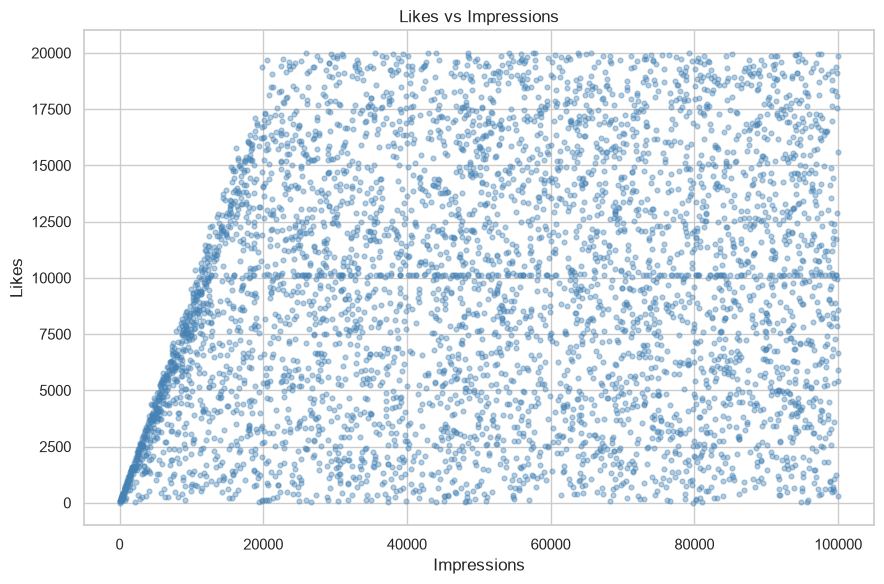

In [38]:
plt.figure(figsize=(9, 6))
plt.scatter(df['impression_count'], df['likes'], alpha=0.4, s=12, color='steelblue')
plt.title('Likes vs Impressions')
plt.xlabel('Impressions')
plt.ylabel('Likes')
plt.tight_layout()
plt.show()

Each dot is one post. There is no clear relationship between likes and impressions: once a post has more than about 20,000 impressions, its likes can be anything from 0 to 20,000, whatever the impressions. Two patterns come from the cleaning step and not from users. The rising edge on the left is the posts whose likes were scaled down to fit under their impressions, and the flat line at about 10,000 likes is the 150 posts whose missing likes were filled with the median.

**Line:** daily engagement trend.

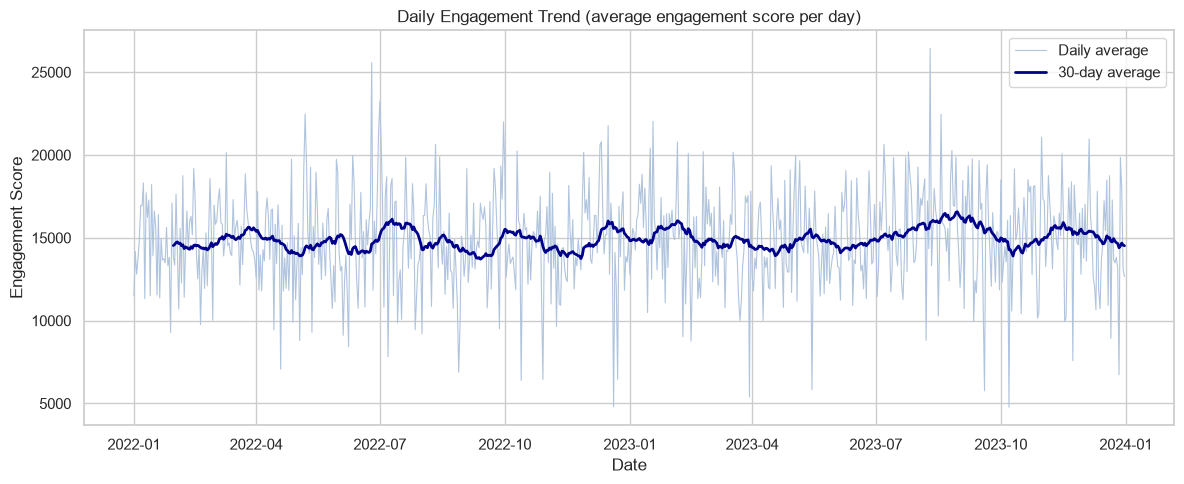

In [39]:
daily = df.groupby('posted_at')['engagement_score'].mean()

plt.figure(figsize=(12, 5))
plt.plot(daily.index, daily.values, color='lightsteelblue', linewidth=0.8, label='Daily average')
plt.plot(daily.index, daily.rolling(30).mean(), color='darkblue', linewidth=2, label='30-day average')
plt.title('Daily Engagement Trend (average engagement score per day)')
plt.xlabel('Date')
plt.ylabel('Engagement Score')
plt.legend()
plt.tight_layout()
plt.show()

The thin line is the average engagement score of the posts published on each day, and the dark line smooths it with a 30-day average (it starts a month in because it needs 30 days of data). The smoothed line stays close to 15,000 for the whole two years, with small ups and downs and no clear growth or decline. The daily line is jumpy because each day only has about 6 or 7 posts.

**Bar:** posts by category.

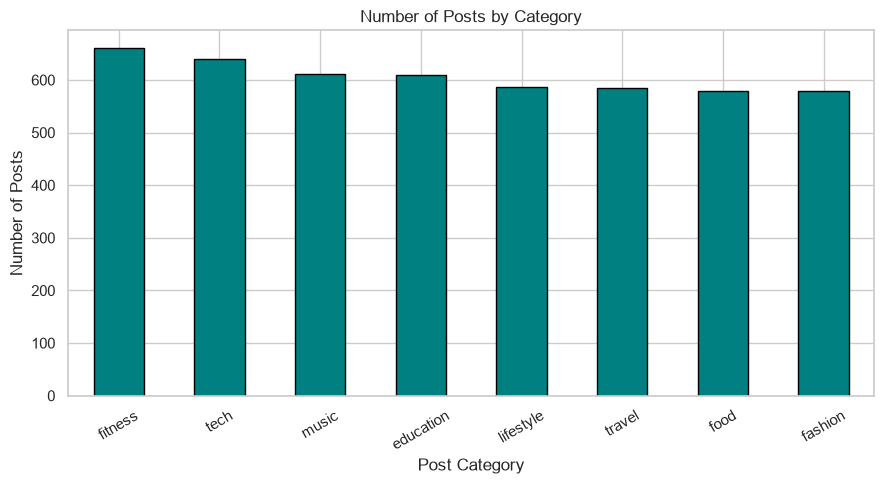

In [40]:
category_counts = df['post_category'].value_counts()

category_counts.plot(kind='bar', figsize=(9, 5), color='teal', edgecolor='black')
plt.title('Number of Posts by Category')
plt.xlabel('Post Category')
plt.ylabel('Number of Posts')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Posts are spread fairly evenly across the eight categories. Fitness has the most (661 posts), and food and fashion have the fewest (579 each).

**Pie:** gender distribution.

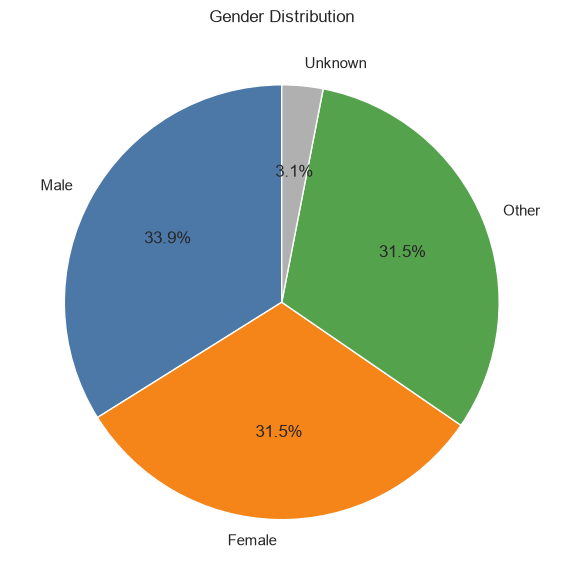

In [41]:
gender_counts = df['gender'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=90,
        colors=['#4C78A8', '#F58518', '#54A24B', '#B0B0B0'], wedgeprops={'edgecolor': 'white'})
plt.title('Gender Distribution')
plt.tight_layout()
plt.show()

Male (33.9%), Female (31.5%) and Other (31.5%) are close to equal. The grey slice is the 148 posts with unknown gender (3.1%), which are the missing values from the cleaning step.

**Histogram:** age.

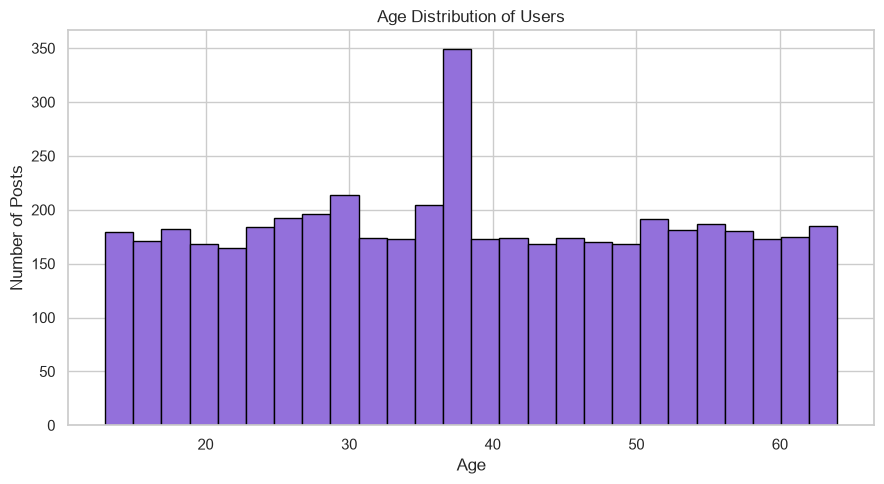

In [42]:
plt.figure(figsize=(9, 5))
plt.hist(df['age'], bins=26, color='mediumpurple', edgecolor='black')
plt.title('Age Distribution of Users')
plt.xlabel('Age')
plt.ylabel('Number of Posts')
plt.tight_layout()
plt.show()

Ages run from 13 to 64 and are spread almost evenly, with roughly 170 to 210 posts in each bin. The one tall bar around age 38 is not real: it is made by the 150 missing ages that were filled with the median age (38).

**Box:** engagement rate.

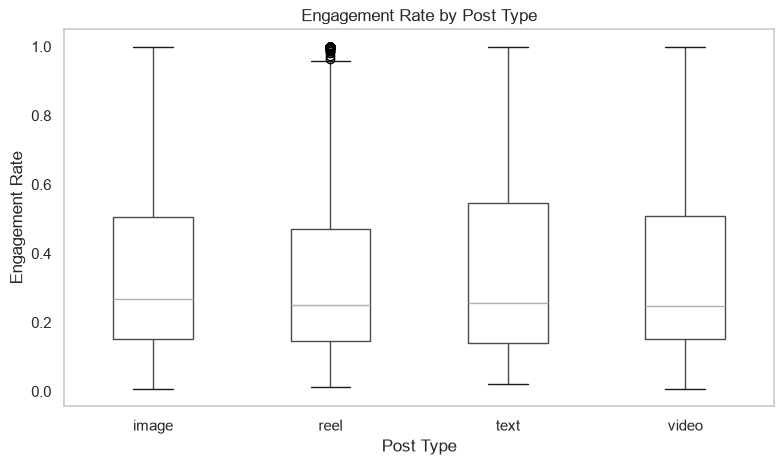

In [43]:
df.boxplot(column='engagement_rate', by='post_type', figsize=(8, 5), grid=False)
plt.title('Engagement Rate by Post Type')
plt.suptitle('')
plt.xlabel('Post Type')
plt.ylabel('Engagement Rate')
plt.tight_layout()
plt.show()

The four post types look almost the same. The middle half of posts sits between roughly 0.15 and 0.5 for each type, and the medians are all about 0.25. The whiskers reach 1.0 because engagement rate is capped there after the cleaning step.

### 🎨 Seaborn

**Count plot:** post type.

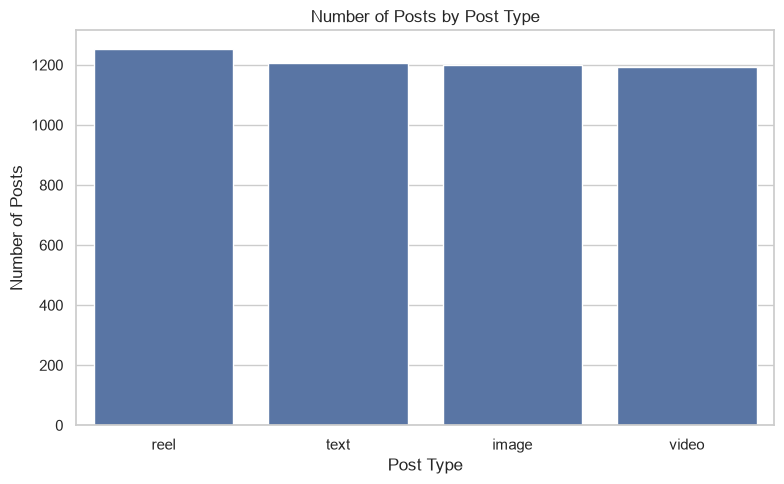

In [44]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='post_type', order=df['post_type'].value_counts().index)
plt.title('Number of Posts by Post Type')
plt.xlabel('Post Type')
plt.ylabel('Number of Posts')
plt.tight_layout()
plt.show()

Reels are the most common post type (1,252 posts), followed by text (1,206), image (1,200) and video (1,192), so the four types are used almost equally.

**Bar plot:** average likes by category.

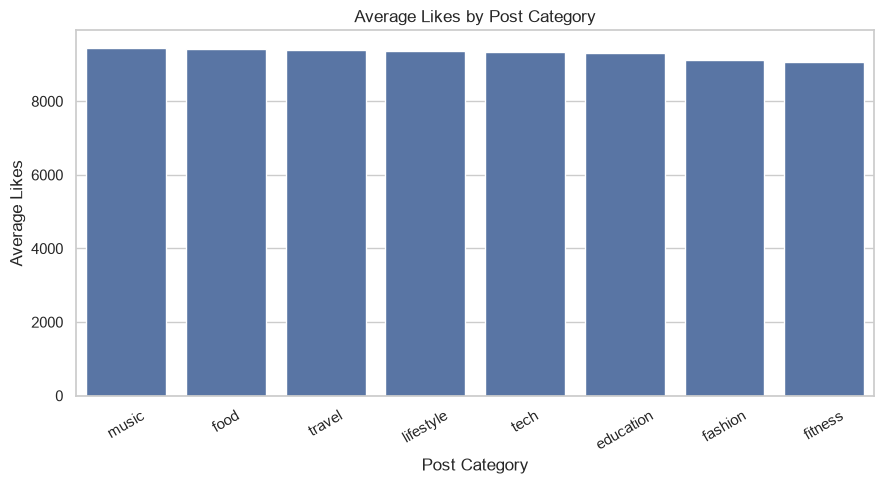

In [45]:
order = df.groupby('post_category')['likes'].mean().sort_values(ascending=False).index

plt.figure(figsize=(9, 5))
sns.barplot(data=df, x='post_category', y='likes', order=order, errorbar=None)
plt.title('Average Likes by Post Category')
plt.xlabel('Post Category')
plt.ylabel('Average Likes')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Average likes are almost identical across the eight categories, from about 9,060 (fitness) to about 9,450 (music), a gap of only about 4%. The bars look alike for the same reason. Music and food are on top, but the likes a post gets do not depend much on its category.

**Violin:** followers vs sentiment.

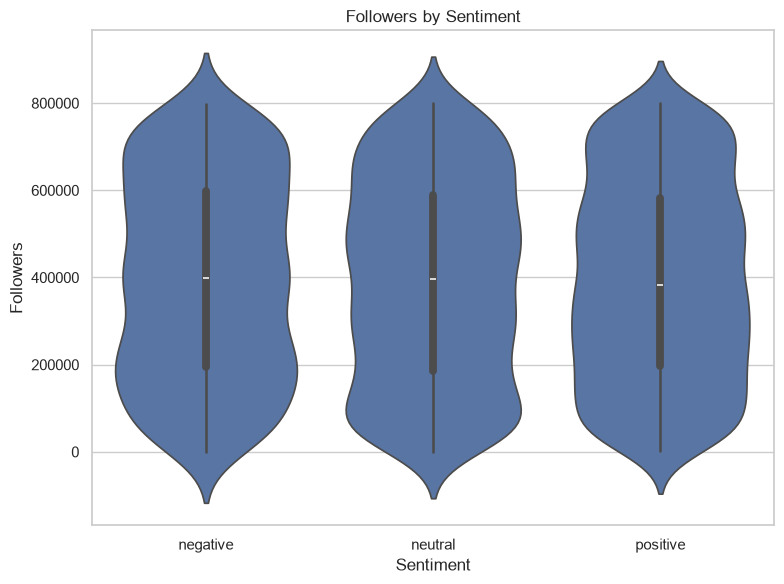

In [46]:
plt.figure(figsize=(8, 6))
sns.violinplot(data=df, x='sentiment', y='follower_count', order=['negative', 'neutral', 'positive'])
plt.title('Followers by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Followers')
plt.tight_layout()
plt.show()

The three violins have almost the same shape: followers are spread from near zero to about 800,000 for every sentiment, and the median (the white dot) is roughly 384,000 to 399,000 in each. Sentiment makes no visible difference to a user's follower count. The violins dip a little below zero only because of smoothing, since the lowest follower count in the data is 87.

**Pair plot:** numeric features.

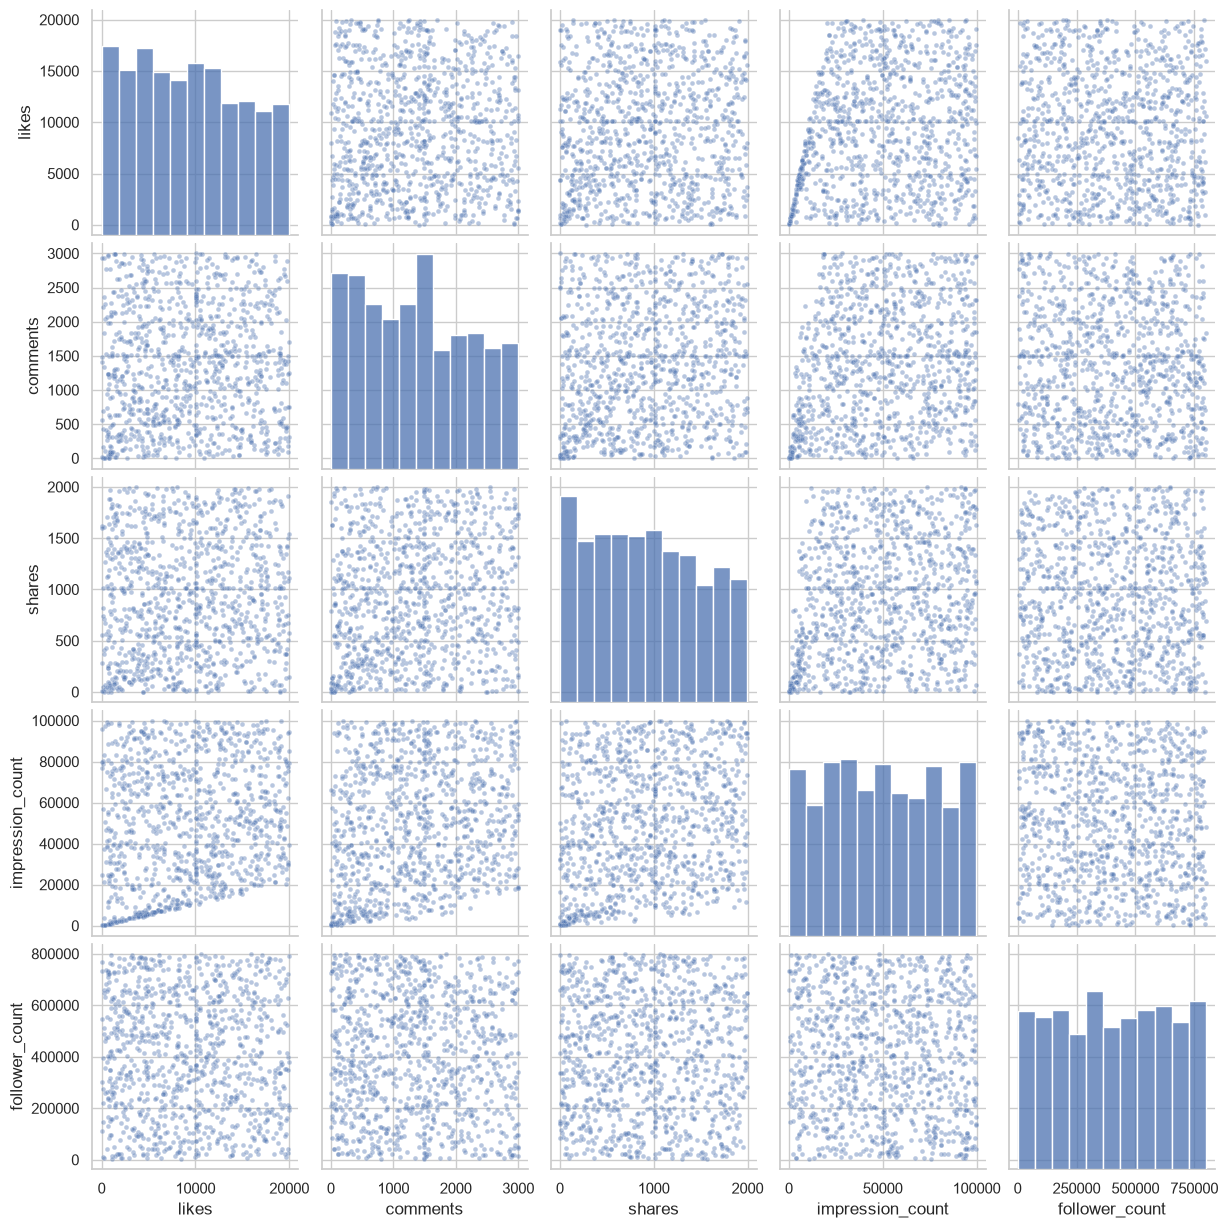

In [47]:
# a random sample of 1,000 posts keeps the plot quick and readable
sample = df.sample(1000, random_state=42)

sns.pairplot(sample, vars=['likes', 'comments', 'shares', 'impression_count', 'follower_count'],
             plot_kws={'alpha': 0.4, 's': 12})
plt.show()

Most pairs show a shapeless cloud of points, which means the numbers are not linked. The exception is every plot against impressions: likes, comments and shares form a sharp rising edge at low impressions. That edge comes from the cleaning step, where posts with more reactions than impressions were scaled down. The histograms on the diagonal show that impressions and followers are spread evenly, while likes, comments and shares lean slightly towards lower values.

**Heatmap:** correlation matrix.

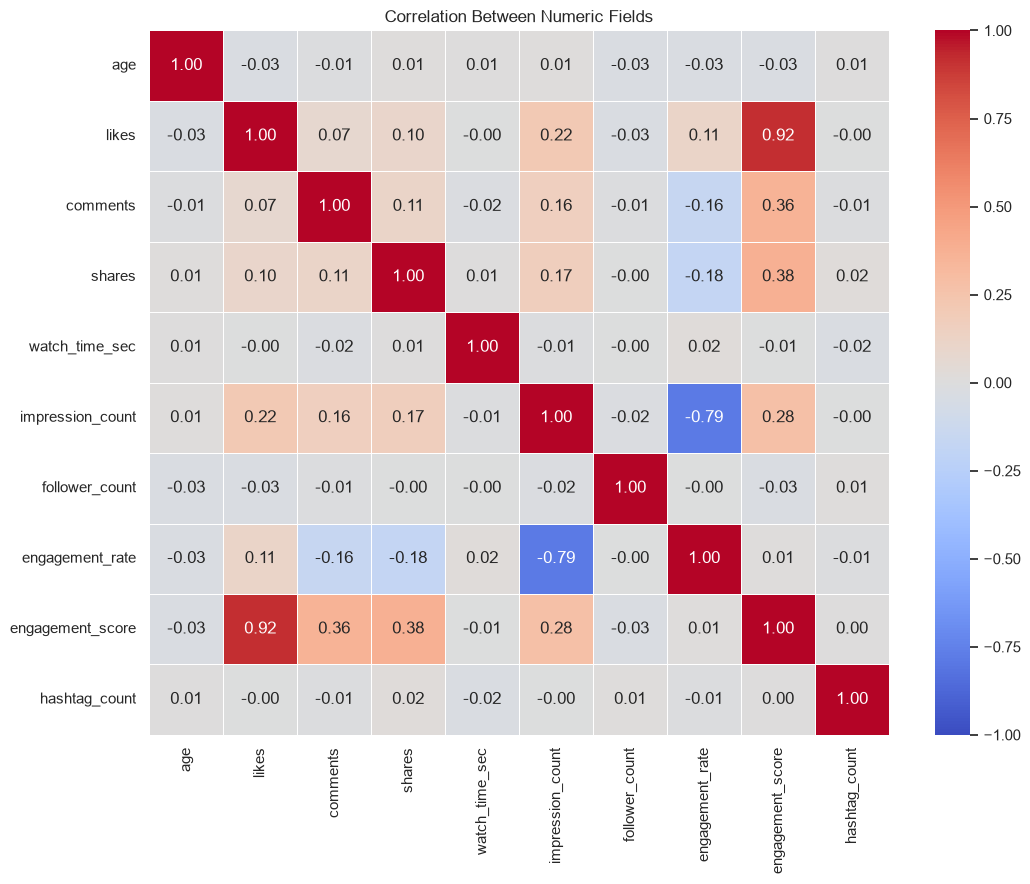

In [48]:
heat_cols = ['age', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count',
             'follower_count', 'engagement_rate', 'engagement_score', 'hashtag_count']

plt.figure(figsize=(11, 9))
sns.heatmap(df[heat_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Between Numeric Fields')
plt.tight_layout()
plt.show()

Almost every pair is close to 0, meaning no relationship. The strongest values are engagement score with likes (0.92), which is expected because likes are the biggest part of the score, and impressions with engagement rate (-0.79): the more impressions a post has, the lower its rate. Engagement rate is also weakly negative with comments (-0.16) and shares (-0.18). Followers, age, watch time and hashtag count are close to 0 with everything else.

**Swarm plot:** engagement vs device.

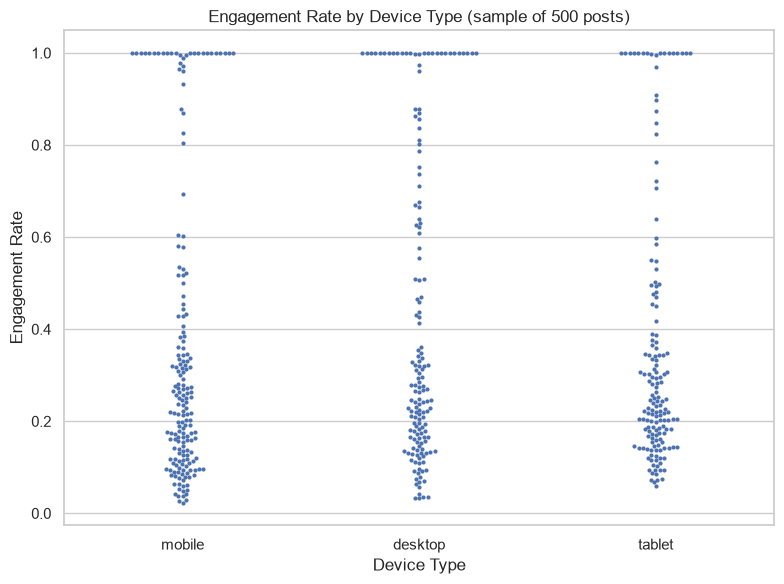

In [49]:
# a random sample of 500 posts, since a swarm plot draws every point separately
swarm_sample = df.sample(500, random_state=1)

plt.figure(figsize=(8, 6))
sns.swarmplot(data=swarm_sample, x='device_type', y='engagement_rate', size=3)
plt.title('Engagement Rate by Device Type (sample of 500 posts)')
plt.xlabel('Device Type')
plt.ylabel('Engagement Rate')
plt.tight_layout()
plt.show()

Each dot is one post from a random sample of 500. All three devices look alike: most posts sit between about 0.05 and 0.4, and a row of dots sits at about 1.0 for each device. That row is the posts that were capped at 100% in the cleaning step. Device type makes no visible difference to engagement rate.

### 🎨 Plotly (Interactive)

The Plotly charts are interactive: hover over a point to see its values, click a legend item to hide it, and drag to zoom.

**Interactive line chart:** monthly engagement rate by post type.

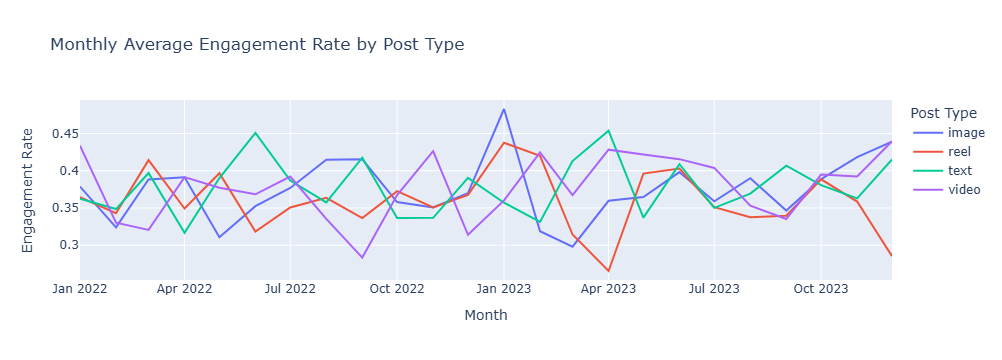

In [50]:
monthly = (df.groupby([df['posted_at'].dt.to_period('M').dt.to_timestamp(), 'post_type'])['engagement_rate']
             .mean().reset_index())

fig = px.line(monthly, x='posted_at', y='engagement_rate', color='post_type',
              title='Monthly Average Engagement Rate by Post Type',
              labels={'posted_at': 'Month', 'engagement_rate': 'Engagement Rate', 'post_type': 'Post Type'})
fig.show()

Each line is one post type's average engagement rate for each month. The lines cross and swing between roughly 0.27 and 0.48, and no post type stays on top, so no type is consistently better. Hover over a point to see its month and value, and click a name in the legend to hide that line.

**Interactive bar chart:** average engagement rate by country.

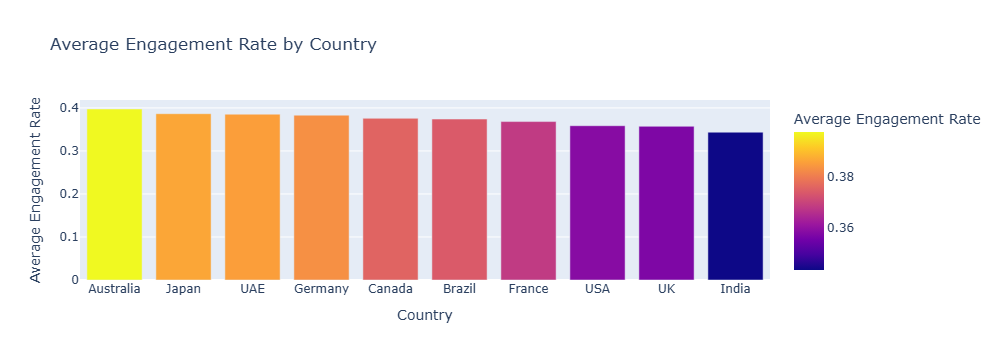

In [51]:
country_rate = (df.groupby('country')['engagement_rate'].mean()
                  .sort_values(ascending=False).reset_index())

fig = px.bar(country_rate, x='country', y='engagement_rate', color='engagement_rate',
             title='Average Engagement Rate by Country',
             labels={'country': 'Country', 'engagement_rate': 'Average Engagement Rate'})
fig.show()

Australia has the highest average engagement rate (about 0.40) and India the lowest (about 0.34), with the other countries in between. The gap looks clear in the chart, but the check at the end of the notebook shows it is no bigger than chance could produce.

**Interactive bubble chart:** impressions vs engagement rate by category.

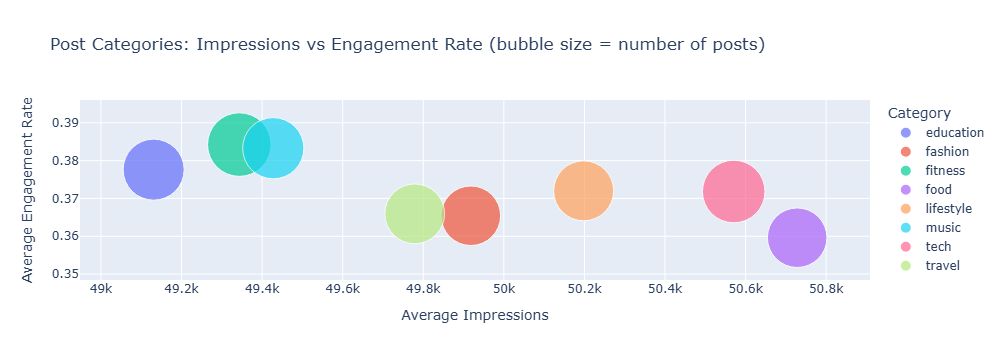

In [52]:
category_stats = df.groupby('post_category').agg(
    avg_impressions=('impression_count', 'mean'),
    avg_engagement_rate=('engagement_rate', 'mean'),
    posts=('post_id', 'count')
).reset_index()

fig = px.scatter(category_stats, x='avg_impressions', y='avg_engagement_rate',
                 size='posts', color='post_category', size_max=45,
                 title='Post Categories: Impressions vs Engagement Rate (bubble size = number of posts)',
                 labels={'avg_impressions': 'Average Impressions',
                         'avg_engagement_rate': 'Average Engagement Rate',
                         'post_category': 'Category'})
fig.show()

Each bubble is a post category. Look at the axis numbers: average impressions only run from about 49,100 to 50,800 and average engagement rate from about 0.36 to 0.385, so the chart is zoomed in and the categories are much closer than the spread suggests. Fitness and music sit highest on engagement rate, and food is lowest. The bubble sizes (number of posts) are all similar.

**Interactive scatter chart:** likes vs impressions, coloured by sentiment.

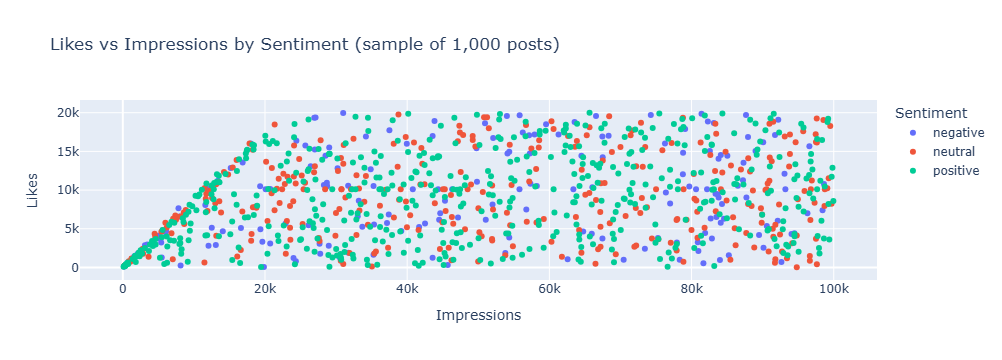

In [53]:
scatter_sample = df.sample(1000, random_state=7)

fig = px.scatter(scatter_sample, x='impression_count', y='likes', color='sentiment',
                 hover_data=['post_type', 'country', 'post_category'],
                 title='Likes vs Impressions by Sentiment (sample of 1,000 posts)',
                 labels={'impression_count': 'Impressions', 'likes': 'Likes', 'sentiment': 'Sentiment'})
fig.show()

Each dot is one post from a random sample of 1,000. The three sentiments are mixed together all over the chart, so sentiment does not separate high-like posts from low-like ones. The rising edge on the left is the cleaned posts again. Hover over a dot to see its post type, country and category.

---
## 💡 Final Insights

Engagement is measured here by the **engagement rate** (likes + comments + shares divided by impressions), with the median shown next to the mean because a few high rates pull the mean up.

### Content Performance

**Which post types have the highest engagement?**

In [54]:
def engagement_table(col):
    return (df.groupby(col).agg(posts=('post_id', 'count'),
                                mean_rate=('engagement_rate', 'mean'),
                                median_rate=('engagement_rate', 'median'),
                                avg_score=('engagement_score', 'mean'))
              .round(4).sort_values('mean_rate', ascending=False))

print(engagement_table('post_type'))

           posts  mean_rate  median_rate   avg_score
post_type                                           
text        1206     0.3785       0.2560  14876.8209
video       1192     0.3774       0.2484  14825.6753
image       1200     0.3755       0.2682  15047.1175
reel        1252     0.3603       0.2497  15006.5990


Text, video and image are level at about 0.38, and reel is lowest at about 0.36. On the median, image comes first (0.268), so the order changes with the measure used. The top three are too close to call, and the check at the end gives p = 0.825, so no post type is clearly ahead.

**What is the best-performing content category?**

In [55]:
print(engagement_table('post_category'))

               posts  mean_rate  median_rate   avg_score
post_category                                           
fitness          661     0.3842       0.2485  14749.6475
music            612     0.3833       0.2598  15281.3660
education        609     0.3776       0.2723  14801.6716
lifestyle        587     0.3720       0.2497  14902.5486
tech             639     0.3718       0.2546  14959.8607
travel           584     0.3659       0.2514  14914.2038
fashion          579     0.3654       0.2625  14824.0000
food             579     0.3596       0.2533  15099.1105


Fitness (0.384) and music (0.383) have the highest average engagement rate, and food (0.360) the lowest. By the median, education comes first (0.272), so the ranking is not stable. The gap between best and worst is only about 0.02, and the check gives p = 0.976, so no category is a real winner.

**Which countries have the highest average engagement rate?**

In [56]:
print(engagement_table('country'))

           posts  mean_rate  median_rate   avg_score
country                                             
Australia    474     0.3976       0.2716  14729.9283
Japan        461     0.3866       0.2656  14754.7093
UAE          487     0.3855       0.2764  14753.9446
Germany      475     0.3833       0.2709  15312.3116
Canada       502     0.3759       0.2641  15045.7490
Brazil       482     0.3742       0.2464  14781.1660
France       484     0.3683       0.2422  15043.2583
USA          486     0.3587       0.2463  14965.8457
UK           483     0.3573       0.2411  14786.6439
India        516     0.3436       0.2457  15198.1647


Australia has the highest average engagement rate (0.398), followed by Japan and the UAE (both about 0.39). India has the lowest (0.344). That is a gap of about 0.05, but each country has only 460 to 520 posts and the check gives p = 0.331, so the ranking could easily change with different data.

### User Trends

**How does age affect engagement?**

In [57]:
print(engagement_table('age_group').sort_index())
print()
print("Correlation between age and engagement rate:", round(df['age'].corr(df['engagement_rate']), 3))

           posts  mean_rate  median_rate   avg_score
age_group                                           
13-24       1049     0.3822       0.2727  14993.1277
25-34        949     0.3769       0.2570  15188.7429
35-44       1068     0.3732       0.2551  15055.2406
45-54        884     0.3744       0.2558  14790.4084
55-64        900     0.3552       0.2412  14625.3644

Correlation between age and engagement rate: -0.026


The youngest group (13-24) has the highest average engagement rate (0.382) and the oldest (55-64) the lowest (0.355), but the trend is slight: the correlation between age and engagement rate is only -0.026. The check shows this small decline is unlikely to be chance (p = 0.021), but it is too small to matter in practice, since age explains well under 1% of the differences in engagement.

**What is the performance difference for verified accounts?**

In [58]:
print(engagement_table('is_verified'))
print()
print(df.groupby('is_verified')[['likes', 'comments', 'shares', 'impression_count', 'follower_count']].mean().round(0))

             posts  mean_rate  median_rate   avg_score
is_verified                                           
False         4380     0.3752       0.2574  14985.0705
True           470     0.3507       0.2366  14518.8191

              likes  comments  shares  impression_count  follower_count
is_verified                                                            
False        9347.0    1414.0   937.0           49771.0        394372.0
True         8931.0    1379.0   943.0           50885.0        382581.0


Verified accounts do slightly worse, not better: their average engagement rate is 0.351 against 0.375 for other accounts, and they get about 4% fewer likes on average (8,931 against 9,347). They also have slightly fewer followers (382,581 against 394,372) and slightly more impressions (50,885 against 49,771). The engagement rate difference just misses the usual 0.05 threshold (p = 0.055), and only 470 posts come from verified accounts, so this is a hint and not a firm result.

### Behavioral Insights

**What is the best time of day for impressions?**

In [59]:
print("Posts with a time of day recorded:", df['posted_at'].dt.hour.ne(0).sum(), "out of", len(df))
print()

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
print("Average impressions by day of the week:")
print(df.groupby('day_of_week')['impression_count'].mean().round(0).reindex(day_order))

Posts with a time of day recorded: 0 out of 4850

Average impressions by day of the week:
day_of_week
Monday       49785.0
Tuesday      50858.0
Wednesday    49863.0
Thursday     48027.0
Friday       49473.0
Saturday     50942.0
Sunday       50152.0
Name: impression_count, dtype: float64


This cannot be answered from the data. `posted_at` holds only the date: none of the 4,850 posts has a time of day, so there is no way to say which hour is best. As the next best thing, impressions by day of the week are shown. Saturday is highest (about 50,900) and Thursday lowest (about 48,000), a gap of about 6%. The check at the end gives p = 0.577, so that gap is within chance and no day of the week is clearly the best.

**How does device type affect watch time?**

In [60]:
print(df.groupby('device_type')['watch_time_sec'].agg(['count', 'mean', 'median']).round(0).sort_values('mean', ascending=False))

             count    mean  median
device_type                       
mobile        1632  4088.0  4111.0
tablet        1615  3978.0  4058.0
desktop       1603  3967.0  3910.0


Mobile has the longest average watch time (4,088 seconds), about 3% more than tablet (3,978) and desktop (3,967). The difference is small and the check gives p = 0.257, so device type does not have a clear effect on watch time.

### Sentiment Analysis

**Which sentiment performs best?**

In [61]:
print(engagement_table('sentiment'))

           posts  mean_rate  median_rate   avg_score
sentiment                                           
negative     960     0.3750       0.2543  14875.1792
neutral     1527     0.3750       0.2532  14849.3870
positive    2363     0.3705       0.2561  15024.6585


No sentiment performs better. Negative and neutral posts both have an average engagement rate of 0.375, and positive posts are very slightly lower at about 0.37. The difference is tiny (p = 0.985), so a post's sentiment says almost nothing about how much engagement it gets.

**How do negative and neutral posts behave?**

In [62]:
behaviour = df.groupby('sentiment')[['likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'follower_count']].mean().round(0)
behaviour['share_of_posts_%'] = (df['sentiment'].value_counts(normalize=True) * 100).round(1)

print(behaviour)

            likes  comments  shares  watch_time_sec  impression_count  follower_count  share_of_posts_%
sentiment                                                                                              
negative   9256.0    1410.0   933.0          4055.0           50192.0        397430.0              19.8
neutral    9167.0    1438.0   936.0          4032.0           49516.0        390568.0              31.5
positive   9418.0    1393.0   940.0          3981.0           49986.0        393243.0              48.7


Negative and neutral posts behave almost exactly like positive ones. Average likes are 9,256 (negative) and 9,167 (neutral) against 9,418 (positive), comments are 1,410 and 1,438 against 1,393, and watch time is 4,055 and 4,032 seconds against 3,981. Negative posts have the longest watch time and neutral posts the most comments, but every gap is small. The real difference is in how many posts there are: positive posts make up 48.7% of all posts, neutral 31.5% and negative 19.8%.

### Are These Differences Real?

In [63]:
# Kruskal-Wallis compares three or more groups, Mann-Whitney compares two.
# A p-value below 0.05 means the difference is unlikely to be down to chance.
results = []

for col in ['post_type', 'post_category', 'country', 'sentiment', 'device_type']:
    groups = [g['engagement_rate'].values for _, g in df.groupby(col)]
    results.append((f"engagement rate by {col}", "Kruskal-Wallis", stats.kruskal(*groups).pvalue))

verified = df.loc[df['is_verified'], 'engagement_rate']
not_verified = df.loc[~df['is_verified'], 'engagement_rate']
results.append(("engagement rate, verified vs not", "Mann-Whitney", stats.mannwhitneyu(verified, not_verified).pvalue))

groups = [g['watch_time_sec'].values for _, g in df.groupby('device_type')]
results.append(("watch time by device_type", "Kruskal-Wallis", stats.kruskal(*groups).pvalue))

groups = [g['impression_count'].values for _, g in df.groupby('day_of_week')]
results.append(("impressions by day_of_week", "Kruskal-Wallis", stats.kruskal(*groups).pvalue))

results.append(("age vs engagement rate", "Spearman", stats.spearmanr(df['age'], df['engagement_rate']).pvalue))

check = pd.DataFrame(results, columns=['comparison', 'test', 'p_value'])
check['p_value'] = check['p_value'].round(3)
check['real difference?'] = np.where(check['p_value'] < 0.05, 'yes', 'no')

print(check.to_string(index=False))

                      comparison           test  p_value real difference?
    engagement rate by post_type Kruskal-Wallis    0.825               no
engagement rate by post_category Kruskal-Wallis    0.976               no
      engagement rate by country Kruskal-Wallis    0.331               no
    engagement rate by sentiment Kruskal-Wallis    0.985               no
  engagement rate by device_type Kruskal-Wallis    0.805               no
engagement rate, verified vs not   Mann-Whitney    0.055               no
       watch time by device_type Kruskal-Wallis    0.257               no
      impressions by day_of_week Kruskal-Wallis    0.577               no
          age vs engagement rate       Spearman    0.021              yes


Almost none of the differences above are real. For post type, category, country, sentiment and device type, the p-values (0.33 to 0.99) are far above 0.05, so the rankings could easily be down to chance. The same goes for watch time by device (0.257) and impressions by day of the week (0.577). Verified accounts are borderline (p = 0.055). The only result under 0.05 is age against engagement rate, and that effect is very small.

The likely reason is that engagement rate in this data depends mainly on impressions (a correlation of -0.79) and hardly at all on who posted or what was posted. So the winners named in this notebook describe this sample, but they should not be treated as rules for what works.

---
## 📝 Summary of Findings

**Data and cleaning**
- 5,000 posts and 19 columns. Six columns had 150 missing values each (age, gender, likes, comments, shares and sentiment).
- Numeric gaps were filled with the median, missing gender was labelled Unknown, and the 150 rows with missing sentiment were dropped, leaving 4,850 posts. There were no duplicate rows.
- 589 posts (12.1%) had more likes, comments and shares than impressions, with engagement rates up to 191.5. Their reactions were scaled down so that no engagement rate is above 1.

**Content performance**
- **Post types:** text, video and image are level at about 0.38 average engagement rate, and reel is lowest at about 0.36. This is not a real difference (p = 0.825).
- **Categories:** fitness (0.384) and music (0.383) are highest and food is lowest (0.360). Not a real difference (p = 0.976).
- **Countries:** Australia is highest (0.398) and India lowest (0.344). Not a real difference (p = 0.331).

**User trends**
- **Age:** engagement rate falls slightly with age, from 0.382 (13-24) to 0.355 (55-64), but the link is very weak (correlation -0.026).
- **Verified accounts:** slightly lower engagement rate (0.351 against 0.375) and about 4% fewer likes. This just misses significance (p = 0.055), and only 470 posts come from verified accounts.

**Behaviour**
- **Time of day** cannot be answered, because the data holds dates only. By weekday, Saturday gets the most impressions (about 50,900) and Thursday the least (about 48,000), which is within chance (p = 0.577).
- **Device:** mobile has the longest watch time (4,088 seconds, against about 3,970 to 3,980 for tablet and desktop). The difference is small (p = 0.257).

**Sentiment**
- No sentiment performs better: engagement rate is 0.375 for negative and neutral posts and about 0.37 for positive ones (p = 0.985).
- Negative and neutral posts behave like positive ones on likes, comments, shares and watch time. Positive posts are simply the most common (48.7% of posts, against 31.5% neutral and 19.8% negative).

**Main takeaway**
- The one strong pattern is that engagement rate falls as impressions rise (correlation -0.79), because likes, comments and shares do not grow with impressions. Beyond that, nothing about the post or the user gives a reliable edge, and the differences between groups are mostly within chance.

**Things to keep in mind**
- The filled and corrected values leave marks on some charts: the tall bar at age 38 and the line at about 10,000 likes come from median filling, and the rising edge in likes against impressions comes from scaling down the 589 posts.
- Engagement rate results for low-impression posts rely on that correction.